# Лабораторная работа №2. Основы языковых моделей

**Учебный профиль:** Greenfield Town  
**Seed:** 42

**Выполнил:** Фролов А.А., 3 курс, группа ИВТ-2.3  
**Дисциплина:** Математика для ИИ, лабораторная работа №2

## Подготовка

Этот notebook читает единый активный профиль `Greenfield Town` из `data/greenfield_town.json` и не использует сеть.

In [1]:
from __future__ import annotations

from collections import Counter, defaultdict
from copy import deepcopy
import json
import math
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True

from pathlib import Path

LAB_DIR = Path.cwd()

SCENARIO_PATH = LAB_DIR / "data" / "greenfield_town.json"
SCENARIO = json.loads(SCENARIO_PATH.read_text(encoding="utf-8"))
print(f"Активный профиль данных: {SCENARIO['title']}")

Активный профиль данных: Greenfield Town


## 1. Мешок слов и n-граммы

В этом шаге нужно превратить строку в список токенов, назначить каждому токену устойчивый индекс и построить бинарный вектор. BoW хранит присутствие токена, но не его позицию; n-граммы ниже покажут, какую часть порядка можно вернуть.

### Маршрут §1: от строки к признакам

**Зачем.** Следующие разделы не умеют читать строку напрямую: им нужны устойчивые номера слов и бинарные признаки документа.

**Порядок.** 1) привести текст к нижнему регистру и выделить английские слова; 2) собрать уникальные токены всех документов и отсортировать их; 3) создать нулевой вектор длины словаря и поставить единицы только известным словам документа; 4) пройти по списку токенов скользящими окнами длины `n`.

**Готово, если.** В Greenfield Town напечатаны словарь из 51 токенов и DTM `12 × 51`; BoW двух переставленных фраз совпадают, но их биграммы различаются.

**Что записать.** Наблюдение о разреженности, причина потери порядка и роль биграмм.

In [2]:
def tokenize(text: str) -> list[str]:
    """Верните список строчных английских слов без пунктуации."""
    # нижний регистр + только латинские буквы
    return re.findall(r"[a-z]+", text.lower())


def build_vocabulary(texts: list[str]) -> dict[str, int]:
    """Верните словарь «токен -> индекс» с алфавитным порядком токенов."""
    all_tokens = set()
    for text in texts:
        all_tokens.update(tokenize(text))
    return {token: index for index, token in enumerate(sorted(all_tokens))}


def doc_to_bow(text: str, vocabulary: dict[str, int]) -> list[int]:
    """Верните бинарный BoW-вектор длины len(vocabulary)."""
    vector = [0] * len(vocabulary)
    for token in tokenize(text):
        if token in vocabulary:  # незнакомые слова пропускаем
            vector[vocabulary[token]] = 1
    return vector


def make_ngrams(tokens: list[str], n: int) -> list[tuple[str, ...]]:
    # скользящее окно длины n
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

Размер словаря: 51
Форма DTM: (12, 51); плотность: 0.113


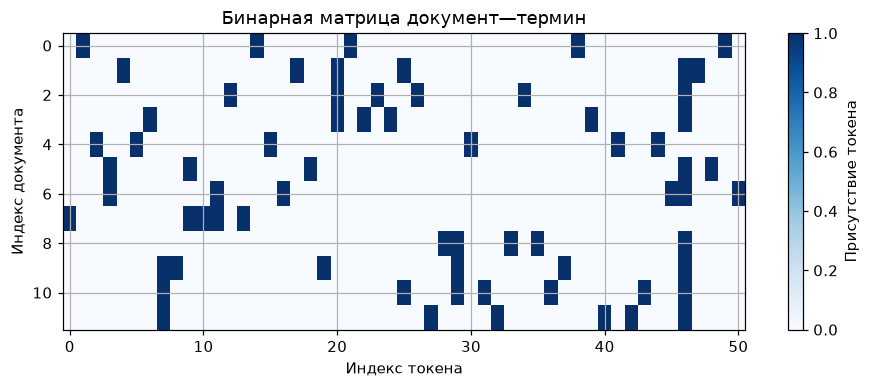

BoW совпадают: True
Биграммы первой фразы: [('garden', 'gate'), ('gate', 'opens')]
Биграммы второй фразы: [('opens', 'gate'), ('gate', 'garden')]


In [3]:
classification_data = SCENARIO["classification"]
CLASS_NAMES = classification_data["class_names"]
DOCS = [record["text"] for record in classification_data["documents"]]
class_to_id = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}
LABELS = torch.tensor(
    [class_to_id[record["label"]] for record in classification_data["documents"]],
    dtype=torch.long,
)

vocabulary = build_vocabulary(DOCS)
document_vectors = torch.tensor([doc_to_bow(doc, vocabulary) for doc in DOCS], dtype=torch.float32)
density = float(document_vectors.mean())
print(f"Размер словаря: {len(vocabulary)}")
print(f"Форма DTM: {tuple(document_vectors.shape)}; плотность: {density:.3f}")

fig, ax = plt.subplots(figsize=(10, 3.5))
dtm_image = ax.imshow(document_vectors.numpy(), aspect="auto", cmap="Blues")
ax.set_xlabel("Индекс токена")
ax.set_ylabel("Индекс документа")
ax.set_title("Бинарная матрица документ—термин")
fig.colorbar(dtm_image, ax=ax, label="Присутствие токена")
plt.show()

first_text, second_text = classification_data["order_examples"]
first = tokenize(first_text)
second = tokenize(second_text)
order_vocabulary = build_vocabulary([first_text, second_text])
print("BoW совпадают:", doc_to_bow(first_text, order_vocabulary) == doc_to_bow(second_text, order_vocabulary))
print("Биграммы первой фразы:", make_ngrams(first, 2))
print("Биграммы второй фразы:", make_ngrams(second, 2))


**Вывод 1.** Почему DTM разрежена? Какой смысловой признак теряет BoW? Почему биграммы не являются универсальным решением?

### Ответ студента 1

- Наблюдение из вывода: словарь получился из 51 токена, DTM имеет форму `12 × 51`, плотность 0.113, то есть единиц всего около 11%. Для фраз `garden gate opens` и `opens gate garden` BoW совпадают (`True`), а биграммы разные: `('garden', 'gate'), ('gate', 'opens')` против `('opens', 'gate'), ('gate', 'garden')`.
- Почему результат получился: в каждом документе 4–7 слов, а словарь общий для всех 12 документов, поэтому в строке почти все 51 позиция нулевые. BoW только отмечает, есть слово в документе или нет, позиция слова никуда не записывается, поэтому перестановка слов вектор не меняет.
- Ограничение метода: BoW теряет порядок слов (и частоту, т.к. вектор бинарный), а незнакомые слова просто выбрасываются. Биграммы возвращают только локальный порядок соседних слов, но число возможных биграмм намного больше числа слов, матрица станет ещё более разреженной, а дальние зависимости всё равно не видны.
- Ответ на вопрос: DTM разрежена, потому что короткий документ содержит малую часть общего словаря. BoW теряет порядок слов, из-за этого `garden gate opens` и `opens gate garden` неотличимы. Биграммы различают эти фразы, но не являются универсальным решением: признаков становится гораздо больше, многие встречаются один раз, и порядок дальше двух слов они не ловят.

## 2. Softmax, кросс-энтропия и классификатор

Контрольная ячейка показывает, как логиты превращаются в вероятности; затем ваша модель должна вернуть именно логиты. Убедитесь, что входные признаки имеют тип `float32`, метки — `torch.long`, а `Softmax` не добавлен в `forward`.

### Маршрут §2.1: сначала ручная математика, затем проверка

**Зачем.** Softmax превращает три сравнительных логита в три вероятностные оценки, а кросс-энтропия показывает, насколько мало вероятности получила правильная метка.

**Порядок.** Для логитов `(2.0, 1.0, 0.5)` отдельно найдите `exp(2.0)`, `exp(1.0)`, `exp(0.5)`; сложите их; разделите каждую экспоненту на сумму; для первого правильного класса возьмите `-log(p_0)`.

**Готово, если.** Вероятности приблизительно равны `(0.629, 0.231, 0.140)`, их сумма равна `1`, а потеря около `0.464`.

**Что записать.** Три экспоненты, их сумму, три вероятности и `-log(p_0)` — в шаблон ответа непосредственно ниже.

### Ответ студента 2.1

- `exp(2.0)`, `exp(1.0)`, `exp(0.5)`: $e^{2} \approx 7.389$, $e^{1} \approx 2.718$, $e^{0.5} \approx 1.649$
- Их сумма: $7.389 + 2.718 + 1.649 = 11.756$
- Softmax с точностью до трёх знаков: $p_0 = 7.389/11.756 \approx 0.629$, $p_1 = 2.718/11.756 \approx 0.231$, $p_2 = 1.649/11.756 \approx 0.140$; сумма $0.629 + 0.231 + 0.140 = 1.000$
- `-log(p_0)`: $-\ln 0.6285 \approx 0.464$
- Почему это совпадает с кросс-энтропией первого правильного класса: кросс-энтропия равна $-\sum_k y_k \ln p_k$, где $y$ — one-hot вектор правильного ответа $(1, 0, 0)$. Все слагаемые, кроме первого, умножаются на 0, остаётся $-\ln p_0$. Контрольная ячейка дала то же самое: softmax `[0.6285 0.2312 0.1402]`, потеря 0.464369 и вручную, и в PyTorch.

Softmax: [0.6285 0.2312 0.1402]
Сумма вероятностей: 1.000000
Потеря вручную: 0.464369; PyTorch: 0.464369
Softmax не меняется после общего сдвига логитов: True


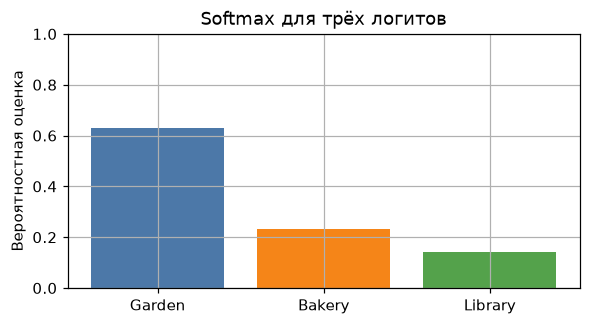

In [4]:
logits_example = torch.tensor([2.0, 1.0, 0.5])
probabilities_example = torch.softmax(logits_example, dim=0)
manual_loss = -math.log(float(probabilities_example[0]))
torch_loss = nn.CrossEntropyLoss()(logits_example.unsqueeze(0), torch.tensor([0]))
shifted_probabilities = torch.softmax(logits_example + 10.0, dim=0)
print("Softmax:", probabilities_example.numpy().round(4))
print(f"Сумма вероятностей: {probabilities_example.sum():.6f}")
print(f"Потеря вручную: {manual_loss:.6f}; PyTorch: {torch_loss.item():.6f}")
print("Softmax не меняется после общего сдвига логитов:", torch.allclose(probabilities_example, shifted_probabilities))
assert torch.isclose(probabilities_example.sum(), torch.tensor(1.0))
assert math.isclose(manual_loss, torch_loss.item(), rel_tol=1e-6)
assert torch.allclose(probabilities_example, shifted_probabilities)

plt.figure(figsize=(6, 3))
plt.bar(CLASS_NAMES, probabilities_example.numpy(), color=["#4c78a8", "#f58518", "#54a24b"])
plt.ylim(0, 1)
plt.ylabel("Вероятностная оценка")
plt.title("Softmax для трёх логитов")
plt.show()


### Маршрут §2.2: собрать и проверить классификатор

**Зачем.** Классификатор должен по одной BoW-строке выбрать один из классов `Garden`, `Bakery`, `Library`.

**Порядок.** В конструкторе создайте первый линейный слой от длины BoW к 24 скрытым признакам, ReLU и второй линейный слой к трём классам. В `forward` примените их слева направо и верните необработанные логиты.

**Готово, если.** Поток имеет форму `(12, 51) → (12, 24) → (12, 3)`, loss уменьшается, а `new_document_logits` имеет форму `(2, 3)`.

**Что записать.** Начальную и финальную loss, форму логитов, смысл `dim=1` и ограничение: уменьшение train loss не доказывает обобщение.

In [5]:
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, output_dim: int):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # softmax не нужен: CrossEntropyLoss сам принимает логиты
        x = self.fc1(x)
        x = self.relu(x)
        return self.fc2(x)

Форма classifier_model.fc1.weight: (24, 51)


Потеря: 1.0895 -> 0.0056
Формы потока: (12, 51) -> (12, 24) -> (12, 3)
Форма логитов: (2, 3)
fresh bread and cakes -> Bakery
readers visit the quiet library -> Library


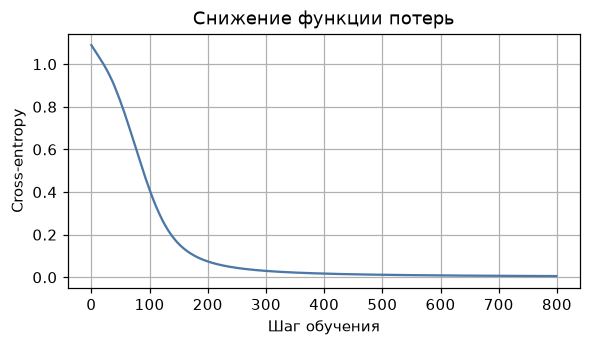

In [6]:
torch.manual_seed(SEED)
classifier_model = SimpleClassifier(input_dim=len(vocabulary), hidden_dim=24, output_dim=len(CLASS_NAMES))
print("Форма classifier_model.fc1.weight:", tuple(classifier_model.fc1.weight.shape))
assert tuple(classifier_model.fc1.weight.shape) == (24, len(vocabulary))
criterion = nn.CrossEntropyLoss()
classifier_optimizer = torch.optim.SGD(classifier_model.parameters(), lr=0.05)
classifier_losses = []
classifier_model.train()
for _ in range(800):
    classifier_optimizer.zero_grad()
    logits = classifier_model(document_vectors)
    classifier_loss = criterion(logits, LABELS)
    classifier_loss.backward()
    classifier_optimizer.step()
    classifier_losses.append(float(classifier_loss.detach()))

classifier_model.eval()
NEW_DOCS = classification_data["new_documents"]
new_document_vectors = torch.tensor([doc_to_bow(doc, vocabulary) for doc in NEW_DOCS], dtype=torch.float32)
with torch.no_grad():
    hidden_vectors = classifier_model.relu(classifier_model.fc1(document_vectors))
    new_document_logits = classifier_model(new_document_vectors)
    predicted_ids = torch.argmax(new_document_logits, dim=1)
print(f"Потеря: {classifier_losses[0]:.4f} -> {classifier_losses[-1]:.4f}")
print("Формы потока:", tuple(document_vectors.shape), "->", tuple(hidden_vectors.shape), "->", (len(DOCS), len(CLASS_NAMES)))
print("Форма логитов:", tuple(new_document_logits.shape))
assert tuple(hidden_vectors.shape) == (len(DOCS), 24)
assert tuple(new_document_logits.shape) == (len(NEW_DOCS), len(CLASS_NAMES))
for document, class_id in zip(NEW_DOCS, predicted_ids.tolist()):
    print(f"{document} -> {CLASS_NAMES[class_id]}")

plt.figure(figsize=(6, 3))
plt.plot(classifier_losses, color="#4c78a8")
plt.xlabel("Шаг обучения")
plt.ylabel("Cross-entropy")
plt.title("Снижение функции потерь")
plt.show()


**Вывод 2.** Почему в `forward` не нужен отдельный `Softmax`? Укажите форму `new_document_logits` и объясните роль `dim=1` в `argmax`.

### Ответ студента 2

- Наблюдение из вывода: loss уменьшилась с 1.0895 до 0.0056 за 800 шагов, поток форм `(12, 51) -> (12, 24) -> (12, 3)`, `new_document_logits` имеет форму `(2, 3)`. Новые документы классифицированы так: `fresh bread and cakes -> Bakery`, `readers visit the quiet library -> Library`.
- Почему результат получился: начальная loss 1.0895 близка к $\ln 3 \approx 1.099$, т.е. сначала модель угадывает почти равновероятно. Документы разных классов почти не пересекаются по словам (bread/cakes/bakery против library/books/readers), поэтому сеть быстро их разделяет. В новых документах есть знакомые слова `bread`, `cakes`, `readers`, `library`, `quiet`, по ним и выбран класс.
- Ограничение метода: обучение шло на 12 документах, и почти нулевая train loss означает, что модель их запомнила, а не что она хорошо работает на новых текстах. Отдельной тестовой выборки нет, поэтому про качество на новых данных сказать ничего нельзя.
- Ответ на вопрос: loss упала 1.0895 -> 0.0056, логиты для двух новых документов имеют форму `(2, 3)` — строка на документ, столбец на класс. `argmax(dim=1)` берёт максимум внутри каждой строки, т.е. выбирает класс отдельно для каждого документа. Softmax в `forward` не нужен, потому что `nn.CrossEntropyLoss` сам применяет log-softmax к логитам, а для `argmax` softmax ничего не меняет (он монотонный). Если добавить его в `forward`, softmax применится дважды.

## 3. Skip-gram и эмбеддинги

Сначала создайте направленные пары «центр — контекст», затем передайте индексы центральных слов в `nn.Embedding` и предскажите индекс контекста. Слой хранит плотный вектор для каждого токена; это статическое представление, поэтому разные значения одного слова не разделяются.

### Маршрут §3: от соседей слова к эмбеддингам

**Зачем.** Skip-gram учит плотный вектор слова по его соседям, поэтому можно сравнить локальные окружения, а не только совпадение букв.

**Порядок.** 1) для каждого центрального токена перечислите все токены окна радиуса 2, кроме него самого; 2) создайте слой `nn.Embedding` и линейный выход к размеру словаря; 3) в `forward` получите embedding центра и логиты контекста; 4) нормируйте все строки векторов, вычислите косинусные оценки и исключите само слово-запрос.

**Готово, если.** Получено 196 направленных пар; поток имеет вид `center_ids (196,) → embedding (196, 12) → logits (196, 33)`; для `gardener` выведены три соседа, но само слово не попало в этот список.

**Что записать.** Один наблюдаемый сосед, общий локальный контекст и ограничение малого корпуса.

In [7]:
def make_skipgram_pairs(tokens: list[str], window_size: int) -> list[tuple[str, str]]:
    pairs = []
    for i, center in enumerate(tokens):
        start = max(0, i - window_size)
        end = min(len(tokens), i + window_size + 1)
        for j in range(start, end):
            if j != i:  # само центральное слово не берём
                pairs.append((center, tokens[j]))
    return pairs


class SkipGramModel(nn.Module):
    def __init__(self, vocab_size: int, embedding_dim: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_ids: torch.Tensor) -> torch.Tensor:
        # вектор центрального слова -> логиты по всему словарю
        return self.output(self.embedding(center_ids))


def nearest_words(word: str, vocabulary: dict[str, int], vectors: torch.Tensor, top_k: int = 3):
    normed = F.normalize(vectors, dim=1)
    word_id = vocabulary[word]
    scores = normed @ normed[word_id]  # косинусное сходство со всеми словами
    id_to_word = {index: token for token, index in vocabulary.items()}
    result = []
    for index in torch.argsort(scores, descending=True).tolist():
        if index == word_id:
            continue
        result.append((id_to_word[index], float(scores[index])))
        if len(result) == top_k:
            break
    return result

Токенов: 67; пар: 196; словарь: 33
Первые направленные пары: [('the', 'gardener'), ('the', 'waters'), ('gardener', 'the'), ('gardener', 'waters'), ('gardener', 'the'), ('waters', 'the')]


Ближайшие слова к 'gardener': [('garden', 0.573), ('baker', 0.464), ('gate', 0.459)]
Ближайшие слова к 'librarian': [('library', 0.655), ('bakery', 0.59), ('baker', 0.533)]


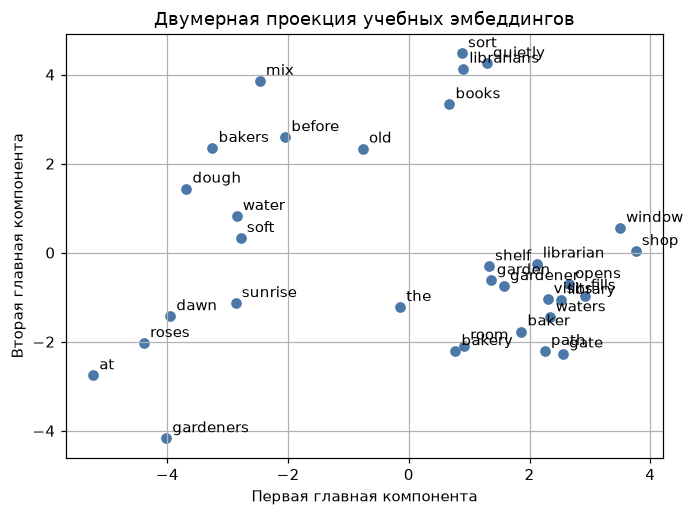

In [8]:
embedding_data = SCENARIO["embedding"]
embedding_lines = embedding_data["lines"]
embedding_tokens = [token for line in embedding_lines for token in tokenize(line)]
embedding_vocabulary = build_vocabulary(embedding_lines)
skipgram_pairs = [
    pair
    for line in embedding_lines
    for pair in make_skipgram_pairs(tokenize(line), window_size=embedding_data["window_size"])
]
center_ids = torch.tensor([embedding_vocabulary[center] for center, _ in skipgram_pairs], dtype=torch.long)
context_ids = torch.tensor([embedding_vocabulary[context] for _, context in skipgram_pairs], dtype=torch.long)
print(f"Токенов: {len(embedding_tokens)}; пар: {len(skipgram_pairs)}; словарь: {len(embedding_vocabulary)}")
print("Первые направленные пары:", skipgram_pairs[:6])
assert all(center != context for center, context in skipgram_pairs)

torch.manual_seed(SEED)
skipgram_model = SkipGramModel(len(embedding_vocabulary), embedding_dim=embedding_data["embedding_dim"])
skipgram_optimizer = torch.optim.Adam(skipgram_model.parameters(), lr=embedding_data["learning_rate"])
skipgram_model.train()
for _ in range(embedding_data["steps"]):
    skipgram_optimizer.zero_grad()
    skipgram_loss = nn.CrossEntropyLoss()(skipgram_model(center_ids), context_ids)
    skipgram_loss.backward()
    skipgram_optimizer.step()

skipgram_model.eval()
embeddings = skipgram_model.embedding.weight.detach()
for query_word in embedding_data["query_words"]:
    print(f"Ближайшие слова к {query_word!r}:", [(word, round(score, 3)) for word, score in nearest_words(query_word, embedding_vocabulary, embeddings)])

matrix = embeddings.numpy()
centered = matrix - matrix.mean(axis=0, keepdims=True)
_, _, right_vectors = np.linalg.svd(centered, full_matrices=False)
coordinates = centered @ right_vectors[:2].T
inverse_embedding_vocabulary = {index: token for token, index in embedding_vocabulary.items()}
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(coordinates[:, 0], coordinates[:, 1], color="#4c78a8")
for index, point in enumerate(coordinates):
    ax.annotate(inverse_embedding_vocabulary[index], point, xytext=(4, 4), textcoords="offset points")
ax.set_title("Двумерная проекция учебных эмбеддингов")
ax.set_xlabel("Первая главная компонента")
ax.set_ylabel("Вторая главная компонента")
plt.show()


**Вывод 3.** Назовите один наблюдаемый близкий вектор и объясните, почему малый учебный корпус не позволяет делать общие выводы о значениях слов.

### Ответ студента 3

- Наблюдение из вывода: получено 196 направленных пар, словарь из 33 токенов. Ближайшие к `gardener`: `garden` (0.573), `baker` (0.464), `gate` (0.459). Ближайшие к `librarian`: `library` (0.655), `bakery` (0.590), `baker` (0.533). Само слово в списки не попало.
- Почему результат получился: `gardener` и `baker` стоят в одинаковых окружениях: `the gardener opens/visits ...` и `the baker opens/visits ...`, т.е. у них общие соседи `the`, `opens`, `visits`. Модель учит вектор так, чтобы по нему предсказывать соседей, поэтому слова с похожими соседями получают похожие векторы. `garden` близко к `gardener`, потому что они стоят в одних и тех же строках в окне радиуса 2.
- Ограничение метода: корпус всего 12 строк и 67 токенов, сходства 0.46–0.66 далеко не единичные и могут сдвинуться при другом seed. Близость `gardener` к `garden` говорит о совместной встречаемости, а не о синонимии. Вектор у слова один, разные значения одного слова не разделяются.
- Ответ на вопрос: наблюдал соседа `baker` у слова `gardener` (0.464): у них одинаковый шаблон `the ___ opens / visits the ...`. Но для общего вывода о смысле слов этого мало: в корпусе по 3–4 предложения на слово, а сходство показывает только похожие окружения именно в этих строках.

## 4. Подсловная токенизация BPE

Эта символьная учебная BPE начинает с символов, считает соседние пары и последовательно сливает самые частые. Сохраняйте различие между частотой слова, частотой пары и упорядоченным списком `merges`; префикс `_` отмечает начало слова, а неизвестный символ заменяется на `<UNK>`.

### Маршрут §4: обучить и применить BPE

**Зачем.** Символьный BPE помогает представить новую словоформу как известные части, когда цельного слова нет в словаре.

**Порядок.** 1) сохраните каждую словоформу как символы с `_` в начале и её частоту; 2) посчитайте соседние пары с весом частоты словоформы; 3) замените только точные соседние токены выбранной пары; 4) повторяйте подсчёт и слияние до лимита словаря; 5) при применении добавьте `_`, замените неизвестный символ на `<UNK>` и исполните `merges` по порядку.

**Готово, если.** Число BPE-токенов не больше 50; слово `garden7` содержит `<UNK>` в результате сегментации.

**Что записать.** Почему частота целой словоформы влияет на пару, что показывает `<UNK>` и почему порядок правил важен.

In [9]:
def initialize_vocabulary(corpus: list[str]):
    vocabulary = defaultdict(int)
    charset = set()
    for word in corpus:
        symbols = ["_"] + list(word)  # "_" отмечает начало слова
        charset.update(symbols)
        vocabulary[" ".join(symbols)] += 1
    return dict(vocabulary), charset


def get_pair_counts(vocabulary: dict[str, int]):
    pair_counts = defaultdict(int)
    for word, count in vocabulary.items():
        symbols = word.split()
        for i in range(len(symbols) - 1):
            # пара встречается столько раз, сколько раз встречается само слово
            pair_counts[(symbols[i], symbols[i + 1])] += count
    return dict(pair_counts)


def merge_pair(vocabulary: dict[str, int], pair: tuple[str, str]):
    # сливаем только целые токены, а не куски других токенов
    pattern = re.compile(r"(?<!\S)" + re.escape(" ".join(pair)) + r"(?!\S)")
    return {pattern.sub("".join(pair), word): count for word, count in vocabulary.items()}


def byte_pair_encoding(corpus: list[str], vocab_size: int):
    vocabulary, charset = initialize_vocabulary(corpus)
    tokens = set(charset)
    merges = []
    while len(tokens) < vocab_size:
        pair_counts = get_pair_counts(vocabulary)
        if not pair_counts:
            break
        best_pair = max(pair_counts, key=pair_counts.get)
        new_token = "".join(best_pair)
        if new_token in tokens:
            break
        vocabulary = merge_pair(vocabulary, best_pair)
        merges.append(best_pair)
        tokens.add(new_token)
    return vocabulary, merges, charset, tokens


def tokenize_word(word: str, merges: list[tuple[str, str]], charset: set[str], unk_token: str = "<UNK>"):
    symbols = [ch if ch in charset else unk_token for ch in "_" + word.lower()]
    # правила применяем строго в том порядке, в котором они выучены
    for left, right in merges:
        i = 0
        while i < len(symbols) - 1:
            if symbols[i] == left and symbols[i + 1] == right:
                symbols[i:i + 2] = [left + right]
            else:
                i += 1
    return symbols

In [10]:
bpe_data = SCENARIO["bpe"]
bpe_corpus = [token for text in bpe_data["corpus"] for token in tokenize(text)]
bpe_vocabulary, merges, charset, bpe_tokens = byte_pair_encoding(bpe_corpus, bpe_data["vocab_size"])
print(f"Размер начального алфавита: {len(charset)}")
print(f"Размер словаря BPE: {len(bpe_tokens)}; число слияний: {len(merges)}")
print("Шаг | сливаемая пара")
for step, pair in enumerate(merges[:10], start=1):
    print(f"{step:3d} | {pair[0]!r} + {pair[1]!r}")
for word in bpe_data["probe_words"]:
    print(f"{word:18s} -> {tokenize_word(word, merges, charset)}")
assert len(bpe_tokens) <= bpe_data["vocab_size"]
assert "<UNK>" in tokenize_word(bpe_data["probe_words"][-1], merges, charset)


Размер начального алфавита: 17
Размер словаря BPE: 50; число слияний: 33
Шаг | сливаемая пара
  1 | '_' + 'g'
  2 | '_g' + 'a'
  3 | 'd' + 'e'
  4 | '_ga' + 'r'
  5 | '_gar' + 'de'
  6 | '_garde' + 'n'
  7 | 'e' + 'r'
  8 | '_' + 'b'
  9 | '_garden' + 'er'
 10 | 'e' + 's'
garden             -> ['_garden']
garden7            -> ['_garden', '<UNK>']


**Вывод 4.** Почему частота пары должна учитывать частоту всего слова? Как `<UNK>` влияет на токенизацию тестового слова с неизвестным символом? Почему порядок `merges` нельзя произвольно менять?

### Ответ студента 4

- Наблюдение из вывода: начальный алфавит 17 символов (с `_`), после 33 слияний словарь BPE имеет ровно 50 токенов. Первые правила: `_ + g`, `_g + a`, `d + e`, `_ga + r`, `_gar + de`, `_garde + n` — модель почти сразу собрала `_garden`. `garden -> ['_garden']`, `garden7 -> ['_garden', '<UNK>']`.
- Почему результат получился: в BPE-корпусе много форм со словом garden (`garden` ×3, `gardener`, `gardens`, `gardeners`), поэтому пары из этих букв самые частые. Частота пары считается с весом частоты словоформы: слово, встретившееся 3 раза, добавляет каждую свою пару 3 раза. Символа `7` в обучающем корпусе нет, поэтому он заменяется на `<UNK>`, а часть `garden` разбирается выученными правилами.
- Ограничение метода: словарь и правила зависят от маленького корпуса, здесь почти все слияния про garden, а редкие слова (`library`, `books`) остаются разбитыми на мелкие части. `<UNK>` теряет информацию о неизвестном символе, и любые незнакомые символы для модели одинаковы.
- Ответ на вопрос: частота словоформы влияет на BPE, потому что пара `g a` в слове `garden`, встретившемся 3 раза, на самом деле встречается 3 раза, и это должно учитываться при выборе слияния. `<UNK>` значит «неизвестный символ BPE», а не неизвестное слово: в `garden7` известная часть всё равно склеилась в `_garden`. Порядок `merges` менять нельзя, потому что каждое правило выучено на результате предыдущих: например, `_garde + n` возможно только после `_gar + de`, иначе при применении получится другая сегментация.

## 5. Счётная триграммная языковая модель

Триграмма оценивает следующее слово по двум предыдущим. Реализуйте отдельно хранение частот, поиск самого длинного доступного контекста и сглаженную вероятность; не смешивайте общий смысл $P$, несглаженную оценку $P_{\mathrm{MLE}}$ и реализованную $P_{+1}$.

### Маршрут §5: посчитать продолжения и вероятность

**Зачем.** Count LM отвечает на вопрос: какое слово чаще всего продолжает левый контекст и с какой сглаженной вероятностью?

**Порядок.** 1) создайте отдельные словари счётчиков для униграмм, биграмм и триграмм; 2) в `train` заполните их скользящими окнами; 3) для прогноза ищите контекст длины 2, затем 1, затем 0; 4) для жадного выбора используйте сырые частоты; 5) для `get_probability` и PPL примените add-one сглаживание; 6) при генерации добавляйте найденный токен к текущей истории.

**Готово для §5, если.** Контекст `['the', 'garden']` продолжается словом `gate`; сумма сглаженных вероятностей равна 1, неизвестная цель имеет положительную вероятность. Конечную PPL проверьте первой ячейкой §6: она использует эти же вероятности на отдельной тестовой последовательности.

**Что записать.** Порядок backoff, роль сглаживания для PPL и ограничение: триграмма видит не более двух предыдущих слов.

In [11]:
class CountLanguageModel:
    def __init__(self, n: int):
        self.n = n
        # ngram_counts[k]: контекст длины k -> Counter следующих слов
        self.ngram_counts = [defaultdict(Counter) for _ in range(n)]
        self.total_unigrams = 0
        self.vocabulary = {"<unk>"}

    def _find_counts(self, context):
        # backoff: сначала контекст из n-1 слов, потом короче
        for order in range(self.n, 1, -1):
            if len(context) >= order - 1:
                key = tuple(context[-(order - 1):])
                counts = self.ngram_counts[order - 1].get(key)
                if counts:
                    return counts
        return None

    def predict_next_token(self, context: list[str] | tuple[str, ...]):
        counts = self._find_counts(context)
        if counts is None:
            counts = self.ngram_counts[0].get((), Counter())  # униграммы
        if not counts:
            return None
        return counts.most_common(1)[0][0]

    def get_probability(self, token: str, context: list[str] | tuple[str, ...]) -> float:
        if token not in self.vocabulary:
            token = "<unk>"
        vocab_size = len(self.vocabulary)
        counts = self._find_counts(context)
        if counts is None:
            counts = self.ngram_counts[0].get((), Counter())
        # сглаживание Лапласа (add-one)
        return (counts[token] + 1) / (sum(counts.values()) + vocab_size)


def train(model: CountLanguageModel, tokens: list[str]) -> None:
    model.vocabulary = set(tokens) | {"<unk>"}
    model.total_unigrams = len(tokens)
    for order in range(1, model.n + 1):
        for i in range(len(tokens) - order + 1):
            context = tuple(tokens[i:i + order - 1])
            next_token = tokens[i + order - 1]
            model.ngram_counts[order - 1][context][next_token] += 1


def generate_text(model: CountLanguageModel, context: list[str], num_tokens: int) -> str:
    history = list(context)
    for _ in range(num_tokens):
        next_token = model.predict_next_token(history)
        if next_token is None:
            break
        history.append(next_token)
    return " ".join(history)


def compute_perplexity(model: CountLanguageModel, tokens: list[str], context_size: int) -> float:
    if not tokens:
        return float("inf")
    log_sum = 0.0
    for i, token in enumerate(tokens):
        context = tokens[max(0, i - context_size):i]  # настоящие предыдущие слова
        log_sum += math.log(model.get_probability(token, context))
    return math.exp(-log_sum / len(tokens))

In [12]:
lm_data = SCENARIO["language_model"]
lm_train_tokens = tokenize(lm_data["train_text"])
lm_test_tokens = tokenize(lm_data["test_text"])

count_lm = CountLanguageModel(n=lm_data["n"])
train(count_lm, lm_train_tokens)
known_context = lm_data["known_context"]
unknown_context = lm_data["unknown_context"]
print("Знакомый контекст:", known_context, "->", count_lm.predict_next_token(known_context))
print("Незнакомый контекст:", unknown_context, "->", count_lm.predict_next_token(unknown_context))
print("P(unknown | unseen context) =", f"{count_lm.get_probability('unknown', unknown_context):.8f}")
probability_sum = sum(count_lm.get_probability(token, known_context) for token in count_lm.vocabulary)
print(f"Сумма P(token | знакомый контекст): {probability_sum:.12f}")
print("Продолжение:", generate_text(count_lm, lm_data["generation_context"], lm_data["generation_length"]))
assert count_lm.get_probability("unknown", unknown_context) > 0
assert math.isclose(probability_sum, 1.0, rel_tol=1e-12, abs_tol=1e-12)


Знакомый контекст: ['the', 'garden'] -> gate
Незнакомый контекст: ['silent', 'garden'] -> gate
P(unknown | unseen context) = 0.05555556
Сумма P(token | знакомый контекст): 1.000000000000
Продолжение: the garden gate opens at dawn the


**Вывод 5.** Опишите порядок отступа к более короткому контексту (backoff). Почему сглаживание Лапласа важно для перплексии? Назовите ограничение триграммной модели при работе с длинным текстом.

### Ответ студента 5

- Наблюдение из вывода: `['the', 'garden'] -> gate`, `['silent', 'garden'] -> gate`, `P(unknown | silent garden) = 0.0556`, сумма сглаженных вероятностей по словарю для знакомого контекста равна 1.000000000000. Жадное продолжение: `the garden gate opens at dawn the`.
- Почему результат получился: в обучающем тексте после `the garden` четыре раза встречаются продолжения: `gate` ×2, `the` ×1, `path` ×1, самое частое — `gate`. Триграммы `silent garden` нет, поэтому модель откатывается к биграммному контексту `garden`, где тоже чаще всего `gate`. Словарь — 13 слов + `<unk>` = 14, после `garden` было 4 продолжения, поэтому $P(\text{<unk>}) = (0+1)/(4+14) = 1/18 \approx 0.0556$, а $P(\text{gate} \mid \text{the garden}) = (2+1)/(4+14) \approx 0.167$. Генерация после `at` выбрала `dawn` (у `dawn` и `dusk` по 1, при равенстве берётся первый встреченный), а потом пошло повторение обучающего текста.
- Ограничение метода: триграмма видит только два предыдущих слова, поэтому не помнит, о чём был текст раньше, и жадная генерация может зацикливаться на частых фразах. Модель умеет только то, что было в одном коротком обучающем тексте.
- Ответ на вопрос: backoff идёт так: сначала ищем контекст из 2 слов (триграмма), если его не было — из 1 слова (биграмма), если и его не было — берём униграммы. Сглаживание Лапласа нужно, чтобы ни у одного токена не было нулевой вероятности: без него одно невиданное слово в тесте дало бы $\log 0 = -\infty$ и бесконечную перплексию. Триграмма не хранит контекст дальше двух предыдущих слов (тему абзаца, начало предложения и т.д.).

## 6. Перплексия, ROUGE и Elo

Перплексия оценивает вероятность тестовых токенов, ROUGE — перекрытие с эталоном, а Elo — попарное предпочтение. Сначала назовите входы и диапазон каждой метрики: эти числа отвечают на разные вопросы и не заменяют друг друга.

In [13]:
perplexity = compute_perplexity(count_lm, lm_test_tokens, context_size=count_lm.n - 1)
print(f"Перплексия на тестовой последовательности: {perplexity:.2f}")
assert math.isfinite(perplexity)


Перплексия на тестовой последовательности: 5.63


### Маршрут §6: измерить разные стороны качества

**Зачем.** PPL, ROUGE, Лайкерт и Elo отвечают на разные вопросы; одной цифрой качество текста здесь не измеряется.

**Порядок.** 1) токенизируйте кандидат и эталон, сформируйте `Counter` n-грамм; 2) для ROUGE-N сложите минимумы кратностей; 3) для LCS заполните таблицу динамического программирования; 4) соедините точность и полноту в ROUGE-L; 5) вычислите ожидаемый балл Elo; 6) обновите оба рейтинга из ожиданий до изменения пары.

**Готово, если.** PPL конечна; все ROUGE лежат в `[0, 1]`, кандидаты A и B дают разные значения, а сумма трёх Elo-рейтингов остаётся `4500`.

**Что записать.** Почему overlap не доказывает истинность; какую сильную сторону и какое ограничение имеет PPL; зачем нужны люди и почему Elo требует многих сравнений.

In [14]:
def ngram_counter(text: str, n: int) -> Counter[tuple[str, ...]]:
    return Counter(make_ngrams(tokenize(text), n))


def rouge_n_recall(generated: str, reference: str, n: int) -> float:
    reference_counts = ngram_counter(reference, n)
    generated_counts = ngram_counter(generated, n)
    total = sum(reference_counts.values())
    if total == 0:
        return 0.0
    overlap = sum(min(count, generated_counts[gram]) for gram, count in reference_counts.items())
    return overlap / total


def lcs_length(left: list[str], right: list[str]) -> int:
    dp = [[0] * (len(right) + 1) for _ in range(len(left) + 1)]
    for i in range(1, len(left) + 1):
        for j in range(1, len(right) + 1):
            if left[i - 1] == right[j - 1]:
                dp[i][j] = dp[i - 1][j - 1] + 1
            else:
                dp[i][j] = max(dp[i - 1][j], dp[i][j - 1])
    return dp[-1][-1]


def rouge_l(generated: str, reference: str, beta: float = 8.0) -> float:
    gen_tokens = tokenize(generated)
    ref_tokens = tokenize(reference)
    if not gen_tokens or not ref_tokens:
        return 0.0
    lcs = lcs_length(gen_tokens, ref_tokens)
    recall = lcs / len(ref_tokens)
    precision = lcs / len(gen_tokens)
    if recall == 0 and precision == 0:
        return 0.0
    return (1 + beta ** 2) * precision * recall / (recall + beta ** 2 * precision)


def expected_score(rating_a: float, rating_b: float) -> float:
    return 1 / (1 + 10 ** ((rating_b - rating_a) / 400))


def update_elo(rating: float, actual_score: float, expected: float, k: float = 32) -> float:
    return rating + k * (actual_score - expected)

Модель | ROUGE-1 | ROUGE-2 | ROUGE-L
A      |   1.000 |   0.600 |   0.831
B      |   0.000 |   0.000 |   0.000


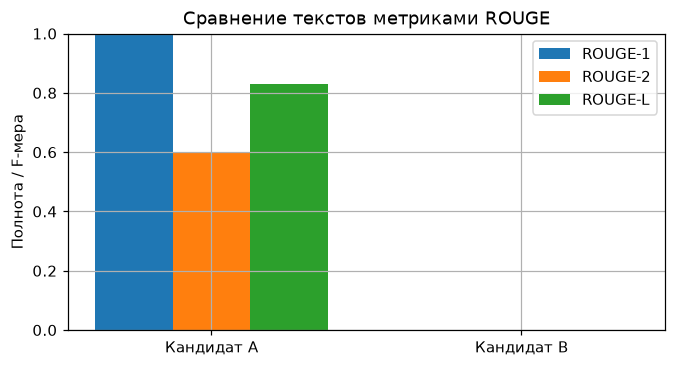

In [15]:
evaluation_data = SCENARIO["evaluation"]
reference = evaluation_data["reference"]
candidate_by_name = {item["name"]: item["text"] for item in evaluation_data["candidates"]}

rows = []
for name, candidate in candidate_by_name.items():
    rows.append((name, rouge_n_recall(candidate, reference, 1), rouge_n_recall(candidate, reference, 2), rouge_l(candidate, reference)))
print("Модель | ROUGE-1 | ROUGE-2 | ROUGE-L")
for name, r1, r2, rl in rows:
    print(f"{name:6s} | {r1:7.3f} | {r2:7.3f} | {rl:7.3f}")
assert all(0 <= value <= 1 for _, *values in rows for value in values)

names = [row[0] for row in rows]
x = np.arange(len(names))
plt.figure(figsize=(7, 3.5))
plt.bar(x - 0.25, [row[1] for row in rows], width=0.25, label="ROUGE-1")
plt.bar(x, [row[2] for row in rows], width=0.25, label="ROUGE-2")
plt.bar(x + 0.25, [row[3] for row in rows], width=0.25, label="ROUGE-L")
plt.xticks(x, ["Кандидат " + name for name in names])
plt.ylim(0, 1)
plt.ylabel("Полнота / F-мера")
plt.title("Сравнение текстов метриками ROUGE")
plt.legend()
plt.show()


In [16]:
matches = [(left, right, float(left_score)) for left, right, left_score in evaluation_data["elo_matches"]]
ratings = {name: 1500.0 for name in evaluation_data["elo_names"]}
for left, right, left_score in matches:
    expected_left = expected_score(ratings[left], ratings[right])
    expected_right = 1 - expected_left
    ratings[left] = update_elo(ratings[left], left_score, expected_left)
    ratings[right] = update_elo(ratings[right], 1 - left_score, expected_right)
print("Итоговые Elo:")
for name, rating in sorted(ratings.items(), key=lambda item: item[1], reverse=True):
    print(f"{name}: {rating:.1f}")
assert math.isclose(sum(ratings.values()), 4500.0, rel_tol=1e-12)


Итоговые Elo:
Bakery-LM: 1501.5
Garden-LM: 1499.3
Library-LM: 1499.2


### Шкала Лайкерта для ручной оценки

Оцените каждый текст по трём независимым критериям: связность, информативность и фактологическая точность.

| Балл | Интерпретация |
| ---: | --- |
| -2 | Критерий практически не выполнен. |
| -1 | Критерий выполнен с существенными недостатками. |
| 0 | Результат приемлем, но без убедительных достоинств. |
| 1 | Критерий выполнен хорошо. |
| 2 | Критерий выполнен полностью и убедительно. |

**Вывод 6.** Почему высокий ROUGE не доказывает фактологическую точность? Почему Elo требует многих попарных сравнений? Какую сильную сторону и какое ограничение имеет перплексия?

### Ответ студента 6

- Наблюдение из вывода: перплексия на тесте `the garden gate opens at dusk` равна 5.63. Кандидат A: ROUGE-1 = 1.000, ROUGE-2 = 0.600, ROUGE-L = 0.831; кандидат B: все три метрики 0. Elo после трёх матчей: Bakery-LM 1501.5, Garden-LM 1499.3, Library-LM 1499.2, сумма 4500.
- Почему результат получился: PPL 5.63 значит, что модель в среднем выбирает как будто из ~5.6 равновероятных слов, а не из 14 слов словаря. A содержит все 6 слов эталона, поэтому ROUGE-1 = 1, но порядок другой, совпадают только 3 из 5 биграмм эталона (`gate opens`, `opens at`, `at dawn`) — ROUGE-2 = 0.6. Наибольшая общая подпоследовательность `the gate opens at dawn` имеет длину 5: полнота 5/6, точность 5/7, отсюда ROUGE-L 0.831. В B нет ни одного слова эталона. В Elo каждая модель один раз выиграла и один раз проиграла, но Bakery-LM победила более сильного на тот момент соперника (Library-LM с 1516.7), поэтому получила больше очков. Сумма сохраняется, потому что один участник получает ровно столько, сколько теряет другой.
- Ограничение метода: ROUGE считает только совпадение слов, PPL — только вероятность готового текста под моделью, Elo по трём матчам почти ничего не говорит (разница между моделями 2.3 очка).
- Ответ на вопрос: ROUGE не доказывает истинность, потому что сравнивает слова с эталоном, а не факты: текст из тех же слов может утверждать неправду, а верный пересказ другими словами получит 0. Сильная сторона PPL — её можно посчитать автоматически на настоящих тестовых токенах и сравнивать модели на одном тесте; ограничение — она не оценивает смысл и правдивость сгенерированного текста и зависит от словаря и токенизации. Ручная оценка добавляет то, чего нет в метриках: связность, полезность и правильность по мнению человека. Elo нельзя оценивать по одному матчу, так как один результат может быть случайным; здесь после трёх матчей у всех по одной победе и рейтинги отличаются всего на 2 очка.

#### Ручная оценка Лайкерта кандидата A

Эти оценки не выводятся из ROUGE: для каждого критерия укажите собственное краткое обоснование по тексту кандидата.

| Критерий | Балл от -2 до 2 | Короткое обоснование |
| --- | ---: | --- |
| Связность | 1 | Фраза читается, но `near garden` без артикля звучит неуклюже. |
| Информативность | 0 | Сообщает то же, что эталон (ворота открываются на рассвете), новых деталей нет. |
| Фактологическая точность | 1 | Не противоречит эталону, но связь `gate` и `garden` размыта: непонятно, что это ворота сада. |

## Итоговый практический результат: мини-портфолио текстового эксперимента

До этого места вы реализовали шесть связанных тем, но это не один искусственный конвейер: BPE, skip-gram и счётная языковая модель решают разные учебные задачи. Ниже готовая базовая ячейка собирает четыре самостоятельных результата в один понятный отчёт. Она использует готовые объекты предыдущих частей и запускается после их выполнения.

| Раздел лекции | Реализованный компонент | Что показывает итоговый отчёт | Проверка и граница вывода | Как переносить на похожую задачу |
| --- | --- | --- | --- | --- |
| §1 | `tokenize`, бинарный BoW, n-граммы | Токены, известные и OOV-слова, активные признаки и биграммы документа | Нулевой BoW означает отсутствие известных признаков; порядок и частоты не становятся признаками классификатора | Заменить документы, затем заново построить словарь и DTM |
| §2 | `SimpleClassifier` | Логиты, вероятности и тематический класс документа | Форма `(1, 3)`, сумма вероятностей равна 1; это не доказательство качества на новых данных | Подать новые документы и метки, затем переобучить модель |
| §3 | skip-gram и `nearest_words` | Три ближайших по косинусному сходству слова | Запрос не должен попасть в собственный список; близость относится только к малому корпусу | Заменить корпус контекстов и обучить эмбеддинги заново |
| §4 | символьный BPE | Разбиение нового слова на подслова и `<UNK>` для неизвестного символа | `<UNK>` — неизвестный символ BPE, а не неизвестное слово LM | Заменить корпус или размер словаря и обучить новые `merges` |
| §5 | счётная триграммная LM | Жадное продолжение, вероятность следующего токена и PPL тестовой последовательности | Конечная PPL использует teacher forcing; триграмма видит не более двух предыдущих токенов | Заменить обучающую и тестовую последовательности, затем обучить LM заново |
| §6 | PPL, ROUGE, Лайкерт и Elo | PPL, три ROUGE-значения, итог Elo и ручная оценка в паспорте | ROUGE не проверяет истинность, Лайкерт субъективен, Elo требует многих сравнений | Заменить кандидата, эталон и журнал сравнений; интерпретировать метрики вместе |

Полный результат — не только напечатанные числа. После базовой ячейки заполните паспорт: зафиксируйте наблюдение, проверку, ограничение и следующий безопасный шаг адаптации.

### Как завершить мини-портфолио

**Зачем.** Это не новая модель и не новая задача: отчёт собирает четыре уже реализованных результата, чтобы у каждого были вход, вывод, проверка и ограничение.

**Готово, если.** Напечатаны девять строк `✓`: форма логитов, нормировка softmax, известные признаки, запрос эмбеддингов, исключение самого слова, `<UNK>` BPE, конечная PPL, диапазон ROUGE и сумма Elo `4500`.

**Что записать.** В паспорте заполните все четыре строки по конкретному выводу отчёта. Укажите вход, наблюдаемый результат, проверенный инвариант, ограничение и одно действие для переноса на похожую задачу.

**Песочница.** Только после базового отчёта разрешено менять значения `CUSTOM_CASE`. Она проверяет OOV и пустой текст, не влияет на базовый результат и не заменяет обязательный паспорт.

In [17]:
portfolio_data = SCENARIO["portfolio"]
PORTFOLIO_CASE = {
    **portfolio_data,
    "perplexity_tokens": lm_test_tokens,
    "candidate": candidate_by_name[portfolio_data["candidate_name"]],
    "reference": reference,
}


def as_tokens(value):
    '''Безопасно приводит строку или последовательность к учебным словным токенам.'''
    if isinstance(value, str):
        return tokenize(value)
    if isinstance(value, (list, tuple)):
        return [token for item in value for token in tokenize(str(item))]
    return []


def bounded_count(value, default=5):
    '''Не даёт необязательной песочнице случайно запросить слишком длинную генерацию.'''
    try:
        return min(max(int(value), 0), 20)
    except (TypeError, ValueError):
        return default


def run_portfolio_case(case, title, strict=False):
    '''Собирает отчёт, не меняя модель, словари, merges или исходные данные.'''
    document = str(case.get("document", ""))
    document_tokens = tokenize(document)
    known_tokens = sorted({token for token in document_tokens if token in vocabulary})
    oov_tokens = sorted({token for token in document_tokens if token not in vocabulary})
    document_bigrams = make_ngrams(document_tokens, 2)
    document_vector = torch.tensor([doc_to_bow(document, vocabulary)], dtype=torch.float32)

    if known_tokens:
        was_training = classifier_model.training
        classifier_model.eval()
        with torch.no_grad():
            document_logits = classifier_model(document_vector)
            document_probabilities = torch.softmax(document_logits, dim=1)
            document_class_id = int(torch.argmax(document_logits, dim=1).item())
        classifier_model.train(was_training)
        classification_message = "Класс выбран по известным бинарным признакам документа."
    else:
        document_logits = None
        document_probabilities = None
        document_class_id = None
        classification_message = "BoW нулевой: у модели нет лексического признака для содержательной классификации."

    query_tokens = as_tokens(case.get("embedding_word", ""))
    embedding_query = query_tokens[0] if len(query_tokens) == 1 else None
    if embedding_query in embedding_vocabulary:
        nearest = nearest_words(embedding_query, embedding_vocabulary, embeddings, top_k=3)
        embedding_message = "Запрос найден в словаре эмбеддингов."
    else:
        nearest = []
        embedding_message = "Запроса нет в словаре эмбеддингов: близкие слова не вычисляются."

    bpe_word = str(case.get("bpe_word", ""))
    if bpe_word:
        bpe_result = tokenize_word(bpe_word, merges, charset)
        bpe_message = "<UNK> здесь означает неизвестный символ, а не неизвестное слово языковой модели."
    else:
        bpe_result = []
        bpe_message = "Пустую строку сегментировать не нужно: в ней нет символов слова."

    lm_context = as_tokens(case.get("lm_context", []))
    num_tokens = bounded_count(case.get("num_tokens", 5))
    predicted_token = count_lm.predict_next_token(lm_context)
    predicted_probability = count_lm.get_probability(predicted_token, lm_context)
    generated_text = generate_text(count_lm, lm_context, num_tokens)
    ppl_tokens = as_tokens(case.get("perplexity_tokens", []))
    portfolio_ppl = compute_perplexity(count_lm, ppl_tokens, context_size=count_lm.n - 1)

    candidate = str(case.get("candidate", ""))
    portfolio_reference = str(case.get("reference", ""))
    rouge_scores = {
        "ROUGE-1": rouge_n_recall(candidate, portfolio_reference, 1),
        "ROUGE-2": rouge_n_recall(candidate, portfolio_reference, 2),
        "ROUGE-L": rouge_l(candidate, portfolio_reference),
    }
    elo_total = sum(ratings.values())
    elo_leader = max(ratings, key=ratings.get)

    report = {
        "classification": {
            "tokens": document_tokens,
            "known_tokens": known_tokens,
            "oov_tokens": oov_tokens,
            "active_features": int(document_vector.sum().item()),
            "logits_shape": tuple(document_logits.shape) if document_logits is not None else None,
            "probability_sum": float(document_probabilities.sum()) if document_probabilities is not None else None,
            "class_name": CLASS_NAMES[document_class_id] if document_class_id is not None else None,
            "message": classification_message,
        },
        "embeddings": {
            "query": embedding_query,
            "nearest": nearest,
            "message": embedding_message,
        },
        "bpe": {"word": bpe_word, "tokens": bpe_result},
        "language_model_and_metrics": {
            "context": lm_context,
            "predicted_token": predicted_token,
            "predicted_probability": predicted_probability,
            "generated_text": generated_text,
            "perplexity": portfolio_ppl,
            "rouge": rouge_scores,
            "elo_leader": elo_leader,
            "elo_total": elo_total,
        },
    }

    print(f"=== {title} ===")
    print("1. BoW + классификатор")
    print("   токены:", document_tokens)
    print("   известные / OOV:", known_tokens, "/", oov_tokens)
    print("   активные признаки:", report["classification"]["active_features"])
    if document_logits is not None:
        print("   logits:", tuple(document_logits.shape), "; вероятности:", document_probabilities[0].numpy().round(4))
        print("   предсказанный класс:", report["classification"]["class_name"])
    print("   ", classification_message)
    print("   биграммы для проверки порядка:", document_bigrams)

    print("2. Skip-gram")
    print("   запрос:", embedding_query)
    print("   ближайшие:", [(word, round(score, 3)) for word, score in nearest])
    print("   ", embedding_message)

    print("3. BPE")
    print(f"   {bpe_word!r} ->", bpe_result)
    print("   ", bpe_message)

    print("4. Count LM + метрики")
    print("   контекст:", lm_context, "->", predicted_token, f"(P={predicted_probability:.6f})")
    print("   жадное продолжение:", generated_text)
    print("   PPL тестовой последовательности:", portfolio_ppl)
    print("   ROUGE:", {name: round(score, 3) for name, score in rouge_scores.items()})
    print(f"   лидер Elo: {elo_leader}; сумма рейтингов: {elo_total:.1f}")

    if strict:
        checks = {
            "логиты имеют форму (1, 3)": report["classification"]["logits_shape"] == (1, 3),
            "вероятности классификатора суммируются к 1": report["classification"]["probability_sum"] is not None and math.isclose(report["classification"]["probability_sum"], 1.0, rel_tol=1e-6, abs_tol=1e-6),
            "базовый документ содержит известные признаки": bool(known_tokens),
            "слово-запрос известно эмбеддингам": embedding_query in embedding_vocabulary,
            "сам запрос исключён из списка соседей": all(word != embedding_query for word, _ in nearest),
            "BPE отмечает неизвестный символ": "<UNK>" in bpe_result,
            "PPL базового теста конечна": math.isfinite(portfolio_ppl),
            "все ROUGE лежат в [0, 1]": all(0 <= score <= 1 for score in rouge_scores.values()),
            "сумма Elo равна 4500": math.isclose(elo_total, 4500.0, rel_tol=1e-12),
        }
        print("Проверки обязательного базового сценария:")
        for check_name, passed in checks.items():
            print(f"   {'✓' if passed else '✗'} {check_name}")
        assert all(checks.values()), "Базовый мини-портфолио не прошёл одну из проверок."
    else:
        print("Диагностика песочницы: отличия от базового случая ожидаемы и не влияют на его проверки.")
    return report


BASELINE_PORTFOLIO = run_portfolio_case(PORTFOLIO_CASE, "Обязательный базовый мини-портфолио", strict=True)
BASELINE_PORTFOLIO_SNAPSHOT = deepcopy(BASELINE_PORTFOLIO)
PORTFOLIO_CASE_SNAPSHOT = deepcopy(PORTFOLIO_CASE)


=== Обязательный базовый мини-портфолио ===
1. BoW + классификатор
   токены: ['fresh', 'bread', 'and', 'cakes']
   известные / OOV: ['and', 'bread', 'cakes', 'fresh'] / []
   активные признаки: 4
   logits: (1, 3) ; вероятности: [0.0073 0.9872 0.0055]
   предсказанный класс: Bakery
    Класс выбран по известным бинарным признакам документа.
   биграммы для проверки порядка: [('fresh', 'bread'), ('bread', 'and'), ('and', 'cakes')]
2. Skip-gram
   запрос: gardener
   ближайшие: [('garden', 0.573), ('baker', 0.464), ('gate', 0.459)]
    Запрос найден в словаре эмбеддингов.
3. BPE
   'garden7' -> ['_garden', '<UNK>']
    <UNK> здесь означает неизвестный символ, а не неизвестное слово языковой модели.
4. Count LM + метрики
   контекст: ['the', 'garden'] -> gate (P=0.166667)
   жадное продолжение: the garden gate opens at dawn the
   PPL тестовой последовательности: 5.634371266046903
   ROUGE: {'ROUGE-1': 1.0, 'ROUGE-2': 0.6, 'ROUGE-L': 0.831}
   лидер Elo: Bakery-LM; сумма рейтингов: 4500.

### Паспорт результата — обязательная часть сдачи

| Блок результата | Вход и наблюдаемый результат | Проверенный инвариант | Ограничение вывода | Следующий шаг адаптации |
| --- | --- | --- | --- | --- |
| BoW + классификатор | `fresh bread and cakes`: 4 известных слова, 0 OOV, вероятности `[0.0073, 0.9872, 0.0055]`, класс `Bakery`. | Логиты формы `(1, 3)`, вероятности в сумме дают 1. | Модель обучена на 12 документах; BoW не видит порядок слов и ничего не знает про OOV-слова. | Для новых документов и меток заново построить словарь и DTM и переобучить классификатор, отложив часть документов на тест. |
| Skip-gram | `gardener` → `garden` (0.573), `baker` (0.464), `gate` (0.459). | Само слово `gardener` не попало в список соседей. | Близость отражает общие соседи в 12 строках корпуса, а не смысловое родство. | Заменить корпус контекстов на больший и обучить эмбеддинги заново, сравнивать соседей только внутри него. |
| BPE | `garden7` → `['_garden', '<UNK>']` при 50 токенах и 33 слияниях. | В разбиении есть `<UNK>` для символа `7`. | `<UNK>` — неизвестный символ BPE, а не неизвестное слово LM; правила подогнаны под слово garden. | Обучить новые `merges` на корпусе новой задачи, при необходимости увеличить `vocab_size`. |
| Count LM + метрики | `the garden` → `gate` (P = 0.167), продолжение `the garden gate opens at dawn the`, PPL = 5.63; ROUGE A = 1.0 / 0.6 / 0.831; лидер Elo `Bakery-LM`. | PPL конечна, ROUGE в `[0, 1]`, сумма Elo = 4500. | Триграмма видит только 2 слова и зацикливается; ROUGE не проверяет истинность; три матча Elo мало. | Обучить LM на новой последовательности, пересчитать PPL на отдельном тесте и ROUGE для нового кандидата и эталона, собрать больше попарных сравнений для Elo. |

Ручная оценка Лайкерта кандидата A: связность `1`, информативность `0`, фактологическая точность `1`. Эти оценки нельзя вывести из ROUGE, потому что ROUGE считает только совпадение слов с эталоном (ROUGE-1 у A = 1.0), а связность и правильность смысла оценивает человек по самому тексту.

### Необязательная песочница `CUSTOM_CASE`

Эта ячейка показывает безопасные границы интерфейса: полностью OOV-документ превращается в нулевой BoW, неизвестное слово не ищется среди эмбеддингов, а пустая тестовая последовательность имеет PPL `inf`. Базовый отчёт выше не меняется. Можно заменить только значения словаря `CUSTOM_CASE`; не меняйте функции и не включайте результат песочницы в обязательный паспорт, если это не требуется преподавателем.

In [18]:
# Меняйте только значения этого словаря. Базовый профиль и обученные объекты выше не меняются.
CUSTOM_CASE = deepcopy(SCENARIO["sandbox"])

CUSTOM_PORTFOLIO = run_portfolio_case(CUSTOM_CASE, "Необязательная песочница", strict=False)
baseline_unchanged = BASELINE_PORTFOLIO == BASELINE_PORTFOLIO_SNAPSHOT and PORTFOLIO_CASE == PORTFOLIO_CASE_SNAPSHOT
assert baseline_unchanged
print("Песочница не меняет базовый результат и его входы:", baseline_unchanged)


=== Необязательная песочница ===
1. BoW + классификатор
   токены: ['zephyrs', 'quizzically']
   известные / OOV: [] / ['quizzically', 'zephyrs']
   активные признаки: 0
    BoW нулевой: у модели нет лексического признака для содержательной классификации.
   биграммы для проверки порядка: [('zephyrs', 'quizzically')]
2. Skip-gram
   запрос: unseenword
   ближайшие: []
    Запроса нет в словаре эмбеддингов: близкие слова не вычисляются.
3. BPE
   '' -> []
    Пустую строку сегментировать не нужно: в ней нет символов слова.
4. Count LM + метрики
   контекст: ['silent', 'garden'] -> gate (P=0.166667)
   жадное продолжение: silent garden gate opens at
   PPL тестовой последовательности: inf
   ROUGE: {'ROUGE-1': 0.0, 'ROUGE-2': 0.0, 'ROUGE-L': 0.0}
   лидер Elo: Bakery-LM; сумма рейтингов: 4500.0
Диагностика песочницы: отличия от базового случая ожидаемы и не влияют на его проверки.
Песочница не меняет базовый результат и его входы: True
